In [ ]:
import os
import random

import numpy as np
import pandas as pd
from joblib import load
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report, f1_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data
from torch_geometric.nn import GATv2Conv, global_mean_pool, global_max_pool
from torch_geometric.nn.aggr import MinAggregation
from ts2vg import NaturalVG, HorizontalVG
from torch_focalloss import MultiClassFocalLoss
import torch.nn.functional as F

import tensorflow as tf
from joblib import load
from keras.utils import to_categorical
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Functions

In [ ]:
# Convert sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data


In [ ]:
class GATv2(nn.Module):
    def __init__(
        self, num_classes=4, input_dim=2, node_hidden=256, edge_hidden=8, heads=6, out_channels=8,
        num_layers=2):
        super().__init__()

        # ====================================
        # NODE EMBEDDING
        # ====================================
        self.node_dense = nn.Linear(input_dim, node_hidden)

        # ====================================
        # EDGE EMBEDDING
        # ====================================
        self.edge_dense = nn.Linear(1, edge_hidden)

        # ====================================
        # GATv2 LAYERS
        # ====================================
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        current_dim = node_hidden

        for _ in range(num_layers):
            self.convs.append(
                GATv2Conv(
                    in_channels=current_dim, out_channels=out_channels, heads=heads, concat=True,
                    edge_dim=edge_hidden, add_self_loops=True, fill_value=0.0)
            )
            current_dim = heads * out_channels
            self.bns.append(nn.BatchNorm1d(current_dim))

        # ====================================
        # CLASSIFICATION
        # ====================================
        self.classifier = nn.Linear(current_dim, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 blocks
        for conv, bn in zip(self.convs, self.bns):
            x = conv(x, edge_index, edge_attr=edge_attr)
            x = bn(x)
            x = F.elu(x)

        # Mean graph pooling
        x = global_mean_pool(x, batch)

        # Classification logits
        return self.classifier(x)


def train_model(model, loader, optimizer, criterion, epochs, device):
    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
        progress_bar = tqdm(loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)

        for batch in progress_bar:
            batch = batch.to(device)
            optimizer.zero_grad()

            # Forward pass
            logits = model(batch)

            # Loss
            loss = criterion(logits, batch.y.long()).mean()

            # Backpropagation
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            batch_size = batch.num_graphs
            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            correct += (predictions == batch.y).sum().item()
            total += batch_size

            # Running metrics
            current_loss = total_loss / total
            current_accuracy = correct / total
            progress_bar.set_postfix(loss=f"{current_loss:.4f}", accuracy=f"{current_accuracy:.4f}")

        # Epoch metrics
        epoch_loss = total_loss / total
        epoch_accuracy = correct / total
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)
        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {epoch_accuracy:.4f}"
        )

    return train_losses, train_accuracies


def evaluate_model(model, loader, criterion, device, model_name, class_labels=(0, 1, 2, 3)):
    # Evaluation mode
    model.eval()
    all_preds = []
    all_labels = []
    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for batch in tqdm(loader, desc=f"Evaluating {model_name}"):
            batch = batch.to(device)

            # Predictions
            logits = model(batch)

            # Validation loss
            loss = criterion(logits, batch.y.long()).mean()
            total_loss += loss.item() * batch.num_graphs
            total_samples += batch.num_graphs

            # Predicted classes
            predictions = logits.argmax(dim=1)
            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(batch.y.cpu().numpy())

    # Convert to NumPy arrays
    y_pred = np.asarray(all_preds)
    y_true = np.asarray(all_labels)

    # Evaluation metrics
    val_loss = total_loss / total_samples
    val_accuracy = accuracy_score(y_true, y_pred)
    val_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"\n{model_name} Evaluation")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_f1:.4f}")

    # Confusion matrix
    sns.set_theme(style="white")
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(class_labels), values_format="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Classification report
    report = classification_report(y_true, y_pred, labels=list(class_labels), digits=4, zero_division=0)
    print(report)

    return {
        "loss": val_loss,
        "accuracy": val_accuracy,
        "macro_f1": val_f1,
        "y_true": y_true,
        "y_pred": y_pred,
        "classification_report": report
    }


## Data Initialization

In [ ]:
X_test, Y_test = load("Data/DL_Test_True.joblib")
X_train, Y_train = load("Data/DataTrain_Multiclass_DL.joblib")

In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# Each training entry corresponds to one subject
subject_indices = list(range(len(Y_train)))

# Hold out 5% of subjects; use 20% of that subset for validation
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value)
X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]
X_abl_train_fold = [X_train[i] for i in abl_train_idx]
Y_abl_train_fold = [Y_train[i] for i in abl_train_idx]
X_abl_val_fold = [X_train[i] for i in abl_val_idx]
Y_abl_val_fold = [Y_train[i] for i in abl_val_idx]
print(len(train_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_test))

# Flatten subject-level labels into one vector
Y_train_fold = flatten(Y_train_fold)
Y_train_fold = Y_train_fold.reshape(-1)
Y_abl_train_fold = flatten(Y_abl_train_fold)
Y_abl_train_fold = Y_abl_train_fold.reshape(-1)
Y_abl_val_fold = flatten(Y_abl_val_fold)
Y_abl_val_fold = Y_abl_val_fold.reshape(-1)
Y_test_fold = flatten(Y_test)
Y_test_fold = Y_test_fold.reshape(-1)

# Flatten subject-level features into arrays
X_train_fold = flatten(X_train_fold)
X_abl_train_fold = flatten(X_abl_train_fold)
X_abl_val_fold = flatten(X_abl_val_fold)
X_test_fold = flatten(X_test)
print(X_train_fold.shape)
print(X_abl_train_fold.shape)
print(X_abl_val_fold.shape)
print(X_test_fold.shape)
Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
Y_abl_train_rs = to_categorical(Y_abl_train_fold)
Y_abl_val_rs = to_categorical(Y_abl_val_fold)

# Prepare labels for class weighting
Y_train_weights = Y_train_fold.reshape(-1).astype("int32")
Y_abl_train_weights = Y_abl_train_fold.reshape(-1).astype("int32")

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)

X_abl_train_t = tf.convert_to_tensor(X_abl_train_fold, dtype=tf.float32)
Y_abl_train_t = tf.convert_to_tensor(Y_abl_train_rs, dtype=tf.int32)

X_abl_val_t = tf.convert_to_tensor(X_abl_val_fold, dtype=tf.float32)
Y_abl_val_t = tf.convert_to_tensor(Y_abl_val_rs, dtype=tf.int32)

X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)


1906
80
21
502
(12891361, 25, 1)
(630399, 25, 1)
(181224, 25, 1)
(3552429, 25, 1)


## Focal Loss Configuration

In [ ]:
if isinstance(Y_abl_train_weights, torch.Tensor):
    y_weights = Y_abl_train_weights.detach().cpu().numpy()
else:
    y_weights = np.asarray(Y_abl_train_weights)

class_counts = np.bincount(y_weights.astype(np.int64).ravel(), minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)
print("Alpha weights:", alpha)
criterion = MultiClassFocalLoss(gamma=1.5, alpha=torch.tensor(alpha, dtype=torch.float32), reduction="none")
criterion = criterion.to(device)


Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]


## Horizontal Visibility Graph

In [ ]:
class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # ====================================
        # NODE EMBEDDING
        # ====================================
        self.node_dense = nn.Linear(3, 256)

        # ====================================
        # EDGE EMBEDDING
        # ====================================
        self.edge_dense = nn.Linear(1, 8)

        # ====================================
        # GATv2 LAYER 1
        # ====================================
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)

        # ====================================
        # GATv2 LAYER 2
        # ====================================
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)

        # ====================================
        # CLASSIFICATION
        # ====================================
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Mean graph pooling
        x = global_mean_pool(x, batch)

        # 4-class logits
        return self.classifier(x)


Train X: (630399, 25, 1)
Train HVG adjacency: (630399, 25, 25)
Validation X: (181224, 25, 1)
Validation HVG adjacency: (181224, 25, 25)
GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3072 | Train Accuracy: 0.6846


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2246 | Train Accuracy: 0.7527


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1631 | Train Accuracy: 0.8115


Evaluating HVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


HVG-GATv2 Evaluation
Validation Loss: 0.1833
Validation Accuracy: 0.7495
Validation Macro-F1: 0.6979


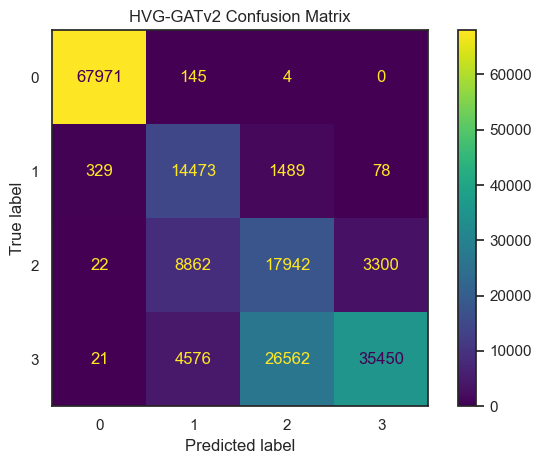

              precision    recall  f1-score   support

           0     0.9946    0.9978    0.9962     68120
           1     0.5159    0.8842    0.6516     16369
           2     0.3901    0.5956    0.4714     30126
           3     0.9130    0.5322    0.6724     66609

    accuracy                         0.7495    181224
   macro avg     0.7034    0.7524    0.6979    181224
weighted avg     0.8209    0.7495    0.7588    181224



In [ ]:
# ====================================
# REPRODUCIBILITY
# ====================================
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ====================================
# HVG ADJACENCY CONSTRUCTION
# ====================================
def build_hvg_adjacency(X):
    if isinstance(X, torch.Tensor):
        X_np = X.detach().cpu().numpy()
    else:
        X_np = np.asarray(X)

    X_np = X_np.astype(np.float32, copy=False)
    N, T, n_features = X_np.shape
    assert n_features == 1
    A_hvg = np.zeros((N, T, T), dtype=np.uint8)

    for i in range(N):
        ts = X_np[i, :, 0]
        vg = HorizontalVG()
        vg.build(ts)
        edges = np.asarray(vg.edges, dtype=np.int64)

        if edges.size > 0:
            src = edges[:, 0]
            dst = edges[:, 1]

            # Undirected adjacency
            A_hvg[i, src, dst] = 1
            A_hvg[i, dst, src] = 1

    return A_hvg

# ====================================
# TRAINING HVG
# ====================================
A_hvg_train = build_hvg_adjacency(X_abl_train_t)
print("Train X:", X_abl_train_t.shape)
print("Train HVG adjacency:", A_hvg_train.shape)

# ====================================
# VALIDATION HVG
# ====================================
A_hvg_test = build_hvg_adjacency(X_abl_val_t)
print("Validation X:", X_abl_val_t.shape)
print("Validation HVG adjacency:", A_hvg_test.shape)


class HVGDataset(Dataset):
    def __init__(self, X, A, y):
        if isinstance(X, torch.Tensor):
            X = X.detach().cpu().numpy()

        if isinstance(y, torch.Tensor):
            y = y.detach().cpu().numpy()

        self.X = np.asarray(X, dtype=np.float32)
        self.A = np.asarray(A, dtype=np.uint8)
        self.y = np.asarray(y, dtype=np.float32)
        assert self.X.shape[1:] == (25, 1)
        assert self.A.shape[1:] == (25, 25)
        assert len(self.X) == len(self.A) == len(self.y)
        self.T = self.X.shape[1]
        self.time = np.linspace(0, 1, self.T, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        # ====================================
        # ORIGINAL VALUES
        # ====================================
        values = self.X[idx, :, 0]
        A = self.A[idx]

        # ====================================
        # NORMALIZED NODE DEGREE
        # INCLUDING SELF-LOOP
        # ====================================
        A_with_self = A.copy()
        np.fill_diagonal(A_with_self, 1)
        degree = ((A_with_self > 0).sum(axis=1) / self.T).astype(np.float32)

        # ====================================
        # NODE FEATURES: (25, 3)
        # ====================================
        node_features = np.stack([values, self.time, degree], axis=1).astype(np.float32)

        # ====================================
        # EDGE INDEX: (2, E)
        # ====================================
        # Original HVG edges without self-loops.
        # GATv2Conv adds self-loops internally.
        A_edges = A.copy()
        np.fill_diagonal(A_edges, 0)
        src, dst = np.nonzero(A_edges)
        edge_index = torch.tensor(np.stack([src, dst]), dtype=torch.long)

        # ====================================
        # EUCLIDEAN EDGE DISTANCES
        # ====================================
        dy = values[src] - values[dst]
        dt = self.time[src] - self.time[dst]
        distances = np.sqrt(dy ** 2 + dt ** 2).astype(np.float32)
        edge_attr = torch.from_numpy(distances[:, None])

        # ====================================
        # CLASS LABEL
        # ====================================
        label = int(np.argmax(self.y[idx]))

        return Data(
            x=torch.from_numpy(node_features), edge_index=edge_index, edge_attr=edge_attr,
            y=torch.tensor(label, dtype=torch.long))

# ====================================
# TRAINING DATASET
# ====================================
train_dataset_hvg = HVGDataset(X=X_abl_train_t, A=A_hvg_train, y=Y_abl_train_t)
train_loader_hvg = DataLoader(train_dataset_hvg, batch_size=256, shuffle=False, num_workers=0)
val_dataset_hvg = HVGDataset(X=X_abl_val_t, A=A_hvg_test, y=Y_abl_val_t)
val_loader_hvg = DataLoader(val_dataset_hvg, batch_size=256, shuffle=False, num_workers=0)
model_hvg = GATv2(num_classes=4).to(device)
print(model_hvg)
optimizer = torch.optim.Adam(model_hvg.parameters(), lr=0.001)
epochs = 10
train_losses, train_accuracies = train_model(
    model=model_hvg, loader=train_loader_hvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_hvg = evaluate_model(
    model=model_hvg, loader=val_loader_hvg, criterion=criterion, device=device, model_name="HVG-GATv2")


## Normal Visibility Graph

In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class NVGDataset(Dataset):
    def __init__(self, X, A, y):
        self.X = np.asarray(X, dtype=np.float32)
        self.A = np.asarray(A, dtype=np.uint8)
        self.y = np.asarray(y, dtype=np.float32)
        assert self.X.shape[1:] == (25, 1)
        assert self.A.shape[1:] == (25, 25)
        assert len(self.X) == len(self.A) == len(self.y)
        self.T = self.X.shape[1]
        self.time = np.linspace(0, 1, self.T, dtype=np.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        # ----------------------------------
        # ORIGINAL VALUES
        # ----------------------------------
        values = self.X[idx, :, 0]
        A = self.A[idx]

        # ----------------------------------
        # NORMALIZED NODE DEGREE
        # Including self-loop
        # ----------------------------------
        A_with_self = A.copy()
        np.fill_diagonal(A_with_self, 1)
        degree = ((A_with_self > 0).sum(axis=1) / self.T).astype(np.float32)

        # ----------------------------------
        # NODE FEATURES: (25, 3)
        # ----------------------------------
        node_features = np.stack([values, self.time, degree], axis=1).astype(np.float32)

        # ----------------------------------
        # EDGE INDEX: (2, E)
        # ----------------------------------
        A_edges = A.copy()
        np.fill_diagonal(A_edges, 0)
        src, dst = np.nonzero(A_edges)
        edge_index = torch.tensor(np.stack([src, dst]), dtype=torch.long)

        # ----------------------------------
        # EUCLIDEAN EDGE DISTANCES
        # ----------------------------------
        dy = values[src] - values[dst]
        dt = self.time[src] - self.time[dst]
        distances = np.sqrt(dy ** 2 + dt ** 2).astype(np.float32)
        edge_attr = torch.from_numpy(distances[:, None])

        # ----------------------------------
        # CLASS LABEL
        # ----------------------------------
        label = int(np.argmax(self.y[idx]))

        return Data(
            x=torch.from_numpy(node_features), edge_index=edge_index, edge_attr=edge_attr,
            y=torch.tensor(label, dtype=torch.long))

if hasattr(X_abl_train_t, "numpy"):
    X_np = X_abl_train_t.numpy()
else:
    X_np = np.asarray(X_abl_train_t)

X_np = X_np.astype(np.float32)
N, T, n_features = X_np.shape
A_nvg = np.zeros((N, T, T), dtype=np.uint8)

for i in range(N):
    ts = X_np[i, :, 0]
    vg = NaturalVG()
    vg.build(ts)
    edges = np.asarray(vg.edges, dtype=np.int64)

    if edges.size > 0:
        src = edges[:, 0]
        dst = edges[:, 1]

        # undirected adjacency
        A_nvg[i, src, dst] = 1
        A_nvg[i, dst, src] = 1

print("X:", X_np.shape)
print("NVG adjacency:", A_nvg.shape)

if hasattr(X_abl_val_t, "numpy"):
    X_np = X_abl_val_t.numpy()
else:
    X_np = np.asarray(X_abl_val_t)

X_np = X_np.astype(np.float32)
N, T, n_features = X_np.shape
A_nvg_test = np.zeros((N, T, T), dtype=np.uint8)

for i in range(N):
    ts = X_np[i, :, 0]
    vg = NaturalVG()
    vg.build(ts)
    edges = np.asarray(vg.edges, dtype=np.int64)

    if edges.size > 0:
        src = edges[:, 0]
        dst = edges[:, 1]

        # undirected adjacency
        A_nvg_test[i, src, dst] = 1
        A_nvg_test[i, dst, src] = 1

print("X:", X_np.shape)
print("NVG adjacency:", A_nvg_test.shape)


X: (630399, 25, 1)
NVG adjacency: (630399, 25, 25)
X: (181224, 25, 1)
NVG adjacency: (181224, 25, 25)


In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
train_dataset_nvg = NVGDataset(X=X_abl_train_t, A=A_nvg, y=Y_abl_train_t)
train_loader_nvg = DataLoader(train_dataset_nvg, batch_size=256, shuffle=False, num_workers=0)
val_dataset_nvg = NVGDataset(X=X_abl_val_t, A=A_nvg_test, y=Y_abl_val_t)
val_loader_nvg = DataLoader(val_dataset_nvg, batch_size=256, shuffle=False, num_workers=0)


In [ ]:
class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # ====================================
        # NODE EMBEDDING
        # ====================================
        self.node_dense = nn.Linear(3, 256)

        # ====================================
        # EDGE EMBEDDING
        # ====================================
        self.edge_dense = nn.Linear(1, 8)

        # ====================================
        # GATv2 LAYER 1
        # ====================================
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)

        # ====================================
        # GATv2 LAYER 2
        # ====================================
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)

        # ====================================
        # CLASSIFICATION
        # ====================================
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # mean graph pooling
        x = global_mean_pool(x, batch)

        # 4-class logits
        return self.classifier(x)


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3206 | Train Accuracy: 0.6731


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2428 | Train Accuracy: 0.7387


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1651 | Train Accuracy: 0.8096


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1801
Validation Accuracy: 0.7862
Validation Macro-F1: 0.7272


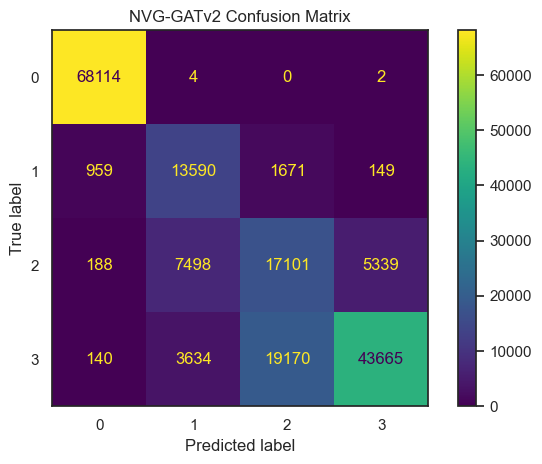

              precision    recall  f1-score   support

           0     0.9815    0.9999    0.9906     68120
           1     0.5496    0.8302    0.6614     16369
           2     0.4507    0.5676    0.5025     30126
           3     0.8883    0.6555    0.7544     66609

    accuracy                         0.7862    181224
   macro avg     0.7175    0.7633    0.7272    181224
weighted avg     0.8200    0.7862    0.7929    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


## Ablations with NVG

GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2852 | Train Accuracy: 0.7024


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2024 | Train Accuracy: 0.7721


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1628 | Train Accuracy: 0.8108


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1650
Validation Accuracy: 0.7983
Validation Macro-F1: 0.7467


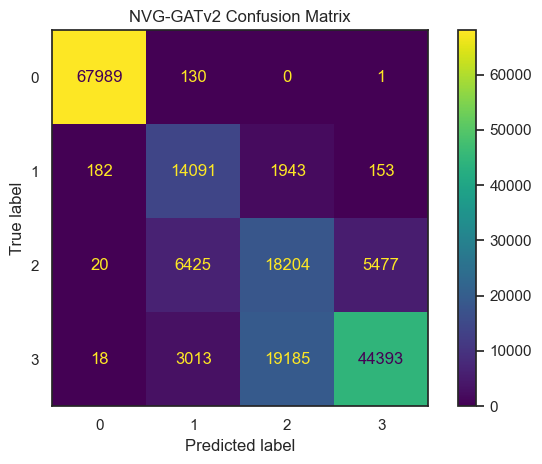

              precision    recall  f1-score   support

           0     0.9968    0.9981    0.9974     68120
           1     0.5956    0.8608    0.7041     16369
           2     0.4628    0.6043    0.5242     30126
           3     0.8874    0.6665    0.7612     66609

    accuracy                         0.7983    181224
   macro avg     0.7357    0.7824    0.7467    181224
weighted avg     0.8316    0.7983    0.8054    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (pool): MinAggregation()
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2933 | Train Accuracy: 0.6915


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2176 | Train Accuracy: 0.7559


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1629 | Train Accuracy: 0.8089


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1680
Validation Accuracy: 0.7982
Validation Macro-F1: 0.7399


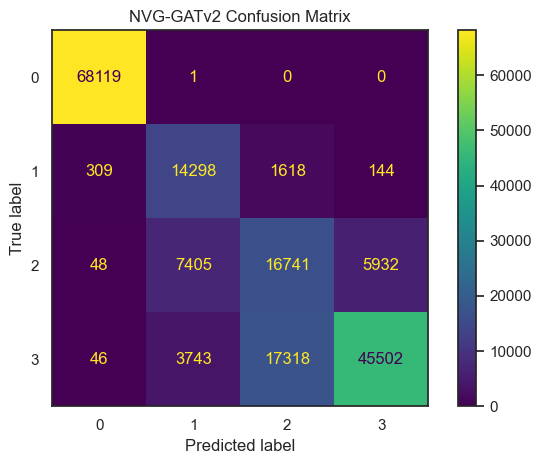

              precision    recall  f1-score   support

           0     0.9941    1.0000    0.9970     68120
           1     0.5619    0.8735    0.6839     16369
           2     0.4692    0.5557    0.5088     30126
           3     0.8822    0.6831    0.7700     66609

    accuracy                         0.7982    181224
   macro avg     0.7269    0.7781    0.7399    181224
weighted avg     0.8267    0.7982    0.8041    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.pool = MinAggregation()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Min graph pooling
        x = self.pool(x, index=batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


### Layer Norm vs Batch Norm

GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2546 | Train Accuracy: 0.7315


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1937 | Train Accuracy: 0.7828


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1677 | Train Accuracy: 0.8058


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1781
Validation Accuracy: 0.8010
Validation Macro-F1: 0.7371


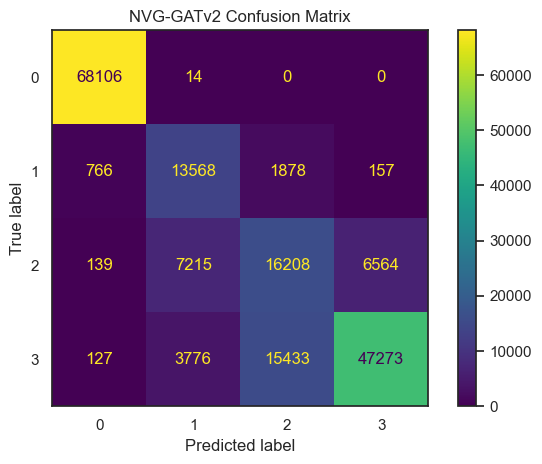

              precision    recall  f1-score   support

           0     0.9851    0.9998    0.9924     68120
           1     0.5522    0.8289    0.6628     16369
           2     0.4835    0.5380    0.5093     30126
           3     0.8755    0.7097    0.7839     66609

    accuracy                         0.8010    181224
   macro avg     0.7241    0.7691    0.7371    181224
weighted avg     0.8223    0.8010    0.8057    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.LayerNorm(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.LayerNorm(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


### GAT layers 

GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 16, heads=6)
  (bn1): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(96, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2816 | Train Accuracy: 0.7088


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1999 | Train Accuracy: 0.7754


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1601 | Train Accuracy: 0.8132


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1685
Validation Accuracy: 0.7847
Validation Macro-F1: 0.7292


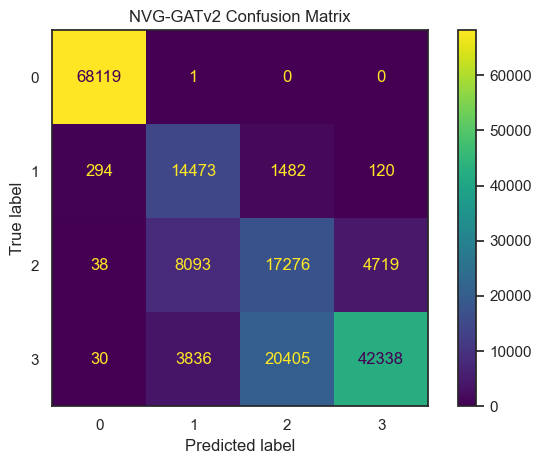

              precision    recall  f1-score   support

           0     0.9947    1.0000    0.9973     68120
           1     0.5482    0.8842    0.6768     16369
           2     0.4411    0.5735    0.4987     30126
           3     0.8974    0.6356    0.7442     66609

    accuracy                         0.7847    181224
   macro avg     0.7204    0.7733    0.7292    181224
weighted avg     0.8266    0.7847    0.7924    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(96)
        self.gatv2conv2 = GATv2Conv(
            in_channels=96, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 16, heads=6)
  (bn1): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(96, 16, heads=6)
  (bn2): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=96, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2777 | Train Accuracy: 0.7097


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1911 | Train Accuracy: 0.7831


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1588 | Train Accuracy: 0.8141


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1735
Validation Accuracy: 0.7824
Validation Macro-F1: 0.7283


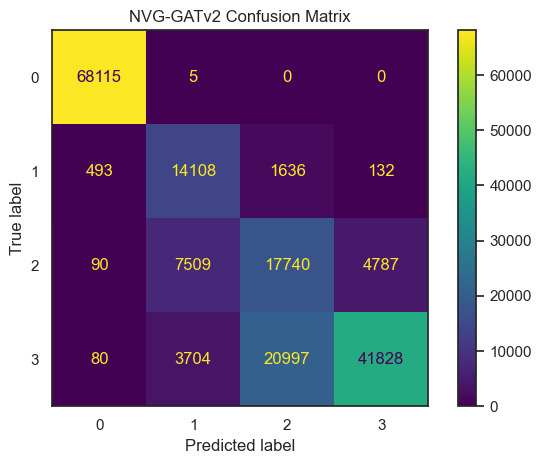

              precision    recall  f1-score   support

           0     0.9904    0.9999    0.9951     68120
           1     0.5571    0.8619    0.6767     16369
           2     0.4394    0.5889    0.5033     30126
           3     0.8948    0.6280    0.7380     66609

    accuracy                         0.7824    181224
   macro avg     0.7204    0.7697    0.7283    181224
weighted avg     0.8245    0.7824    0.7901    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(96)
        self.gatv2conv2 = GATv2Conv(
            in_channels=96, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(96)
        self.classifier = nn.Linear(96, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 16, heads=6)
  (bn2): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=96, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2833 | Train Accuracy: 0.7072


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1936 | Train Accuracy: 0.7822


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1623 | Train Accuracy: 0.8118


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1791
Validation Accuracy: 0.7440
Validation Macro-F1: 0.6951


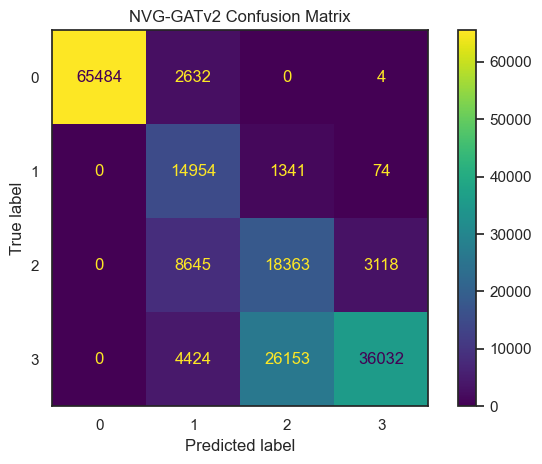

              precision    recall  f1-score   support

           0     1.0000    0.9613    0.9803     68120
           1     0.4878    0.9136    0.6360     16369
           2     0.4004    0.6095    0.4833     30126
           3     0.9185    0.5409    0.6809     66609

    accuracy                         0.7440    181224
   macro avg     0.7017    0.7563    0.6951    181224
weighted avg     0.8241    0.7440    0.7565    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(96)
        self.classifier = nn.Linear(96, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 4, heads=6)
  (bn1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(24, 4, heads=6)
  (bn2): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=24, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3059 | Train Accuracy: 0.6894


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2193 | Train Accuracy: 0.7571


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1666 | Train Accuracy: 0.8064


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1829
Validation Accuracy: 0.7835
Validation Macro-F1: 0.7189


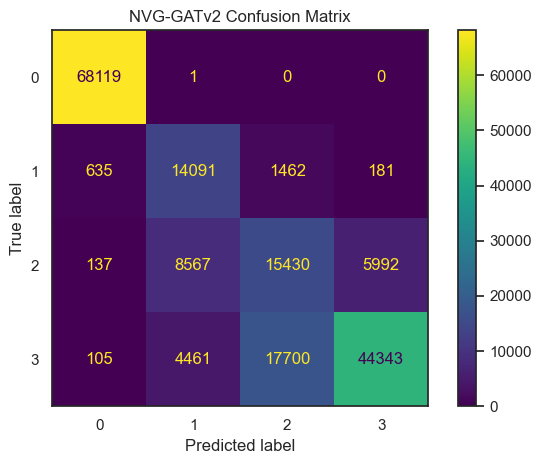

              precision    recall  f1-score   support

           0     0.9873    1.0000    0.9936     68120
           1     0.5196    0.8608    0.6480     16369
           2     0.4461    0.5122    0.4768     30126
           3     0.8778    0.6657    0.7572     66609

    accuracy                         0.7835    181224
   macro avg     0.7077    0.7597    0.7189    181224
weighted avg     0.8148    0.7835    0.7896    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(24)
        self.gatv2conv2 = GATv2Conv(
            in_channels=24, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(24)
        self.classifier = nn.Linear(24, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 4, heads=6)
  (bn1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=24, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2971 | Train Accuracy: 0.6947


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2142 | Train Accuracy: 0.7609


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1745 | Train Accuracy: 0.7974


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1762
Validation Accuracy: 0.7540
Validation Macro-F1: 0.7095


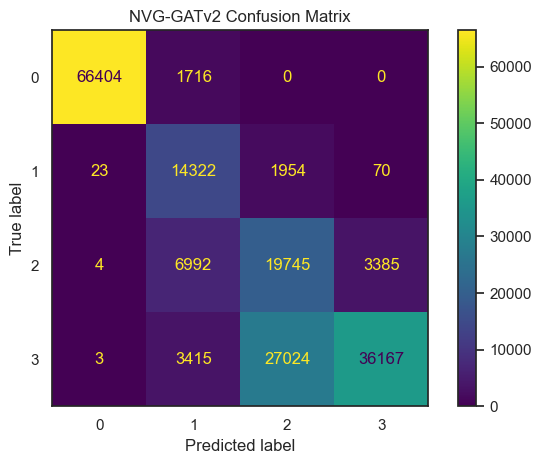

              precision    recall  f1-score   support

           0     0.9995    0.9748    0.9870     68120
           1     0.5416    0.8749    0.6690     16369
           2     0.4053    0.6554    0.5008     30126
           3     0.9128    0.5430    0.6809     66609

    accuracy                         0.7540    181224
   macro avg     0.7148    0.7620    0.7095    181224
weighted avg     0.8275    0.7540    0.7650    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(24)
        self.classifier = nn.Linear(24, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 4, heads=6)
  (bn1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(24, 4, heads=6)
  (bn2): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv3): GATv2Conv(24, 4, heads=6)
  (bn3): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=24, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3082 | Train Accuracy: 0.6879


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2237 | Train Accuracy: 0.7550


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1613 | Train Accuracy: 0.8118


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1835
Validation Accuracy: 0.7499
Validation Macro-F1: 0.6930


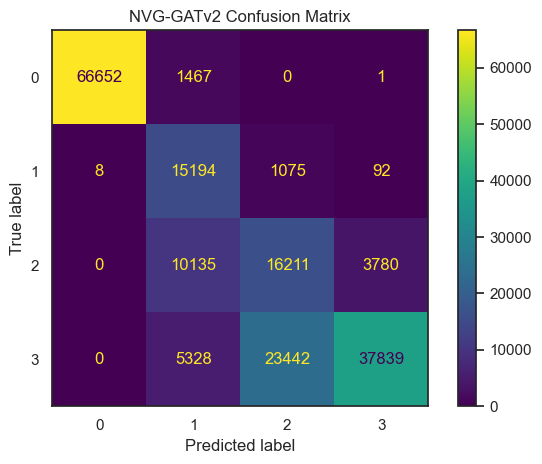

              precision    recall  f1-score   support

           0     0.9999    0.9784    0.9890     68120
           1     0.4730    0.9282    0.6266     16369
           2     0.3980    0.5381    0.4576     30126
           3     0.9071    0.5681    0.6986     66609

    accuracy                         0.7499    181224
   macro avg     0.6945    0.7532    0.6930    181224
weighted avg     0.8182    0.7499    0.7612    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(24)
        self.gatv2conv2 = GATv2Conv(
            in_channels=24, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(24)
        self.gatv2conv3 = GATv2Conv(
            in_channels=24, out_channels=4, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn3 = nn.BatchNorm1d(24)
        self.classifier = nn.Linear(24, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # GATv2 block 3
        x = self.gatv2conv3(x, edge_index, edge_attr=edge_attr)
        x = self.bn3(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv3): GATv2Conv(48, 8, heads=6)
  (bn3): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2932 | Train Accuracy: 0.6992


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2009 | Train Accuracy: 0.7759


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1593 | Train Accuracy: 0.8148


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1817
Validation Accuracy: 0.7544
Validation Macro-F1: 0.6946


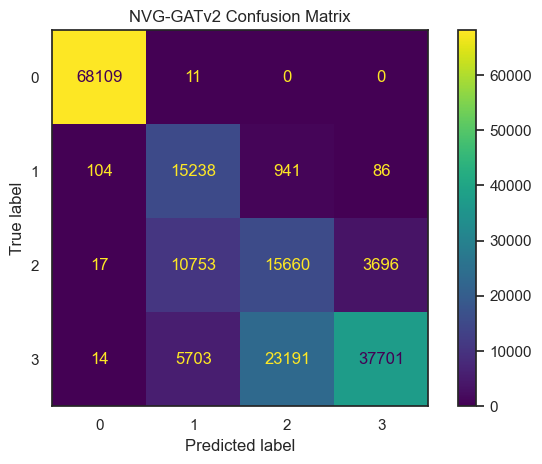

              precision    recall  f1-score   support

           0     0.9980    0.9998    0.9989     68120
           1     0.4806    0.9309    0.6339     16369
           2     0.3935    0.5198    0.4480     30126
           3     0.9088    0.5660    0.6976     66609

    accuracy                         0.7544    181224
   macro avg     0.6953    0.7541    0.6946    181224
weighted avg     0.8180    0.7544    0.7636    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.gatv2conv3 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn3 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # GATv2 block 3
        x = self.gatv2conv3(x, edge_index, edge_attr=edge_attr)
        x = self.bn3(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


GATv2(
  (node_dense): Linear(in_features=3, out_features=256, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(256, 16, heads=6)
  (bn1): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(96, 16, heads=6)
  (bn2): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv3): GATv2Conv(96, 16, heads=6)
  (bn3): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=96, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2860 | Train Accuracy: 0.7068


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2009 | Train Accuracy: 0.7783


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1567 | Train Accuracy: 0.8167


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1728
Validation Accuracy: 0.7869
Validation Macro-F1: 0.7272


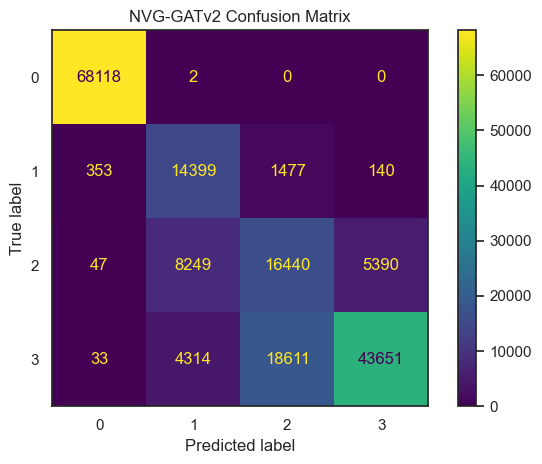

              precision    recall  f1-score   support

           0     0.9937    1.0000    0.9968     68120
           1     0.5340    0.8797    0.6646     16369
           2     0.4501    0.5457    0.4933     30126
           3     0.8876    0.6553    0.7540     66609

    accuracy                         0.7869    181224
   macro avg     0.7163    0.7702    0.7272    181224
weighted avg     0.8228    0.7869    0.7938    181224



In [ ]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GATv2(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 256)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=256, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(96)
        self.gatv2conv2 = GATv2Conv(
            in_channels=96, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(96)
        self.gatv2conv3 = GATv2Conv(
            in_channels=96, out_channels=16, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn3 = nn.BatchNorm1d(96)
        self.classifier = nn.Linear(96, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # GATv2 block 3
        x = self.gatv2conv3(x, edge_index, edge_attr=edge_attr)
        x = self.bn3(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GATv2(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")


### Node dimensions

Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2794 | Train Accuracy: 0.7092


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2072 | Train Accuracy: 0.7695


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 03/10 | Train Loss: 0.1809 | Train Accuracy: 0.7931


... (12 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1611 | Train Accuracy: 0.8117


Evaluating NVG-GATv2-Node128:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2-Node128 Evaluation
Validation Loss: 0.1688
Validation Accuracy: 0.7868
Validation Macro-F1: 0.7305


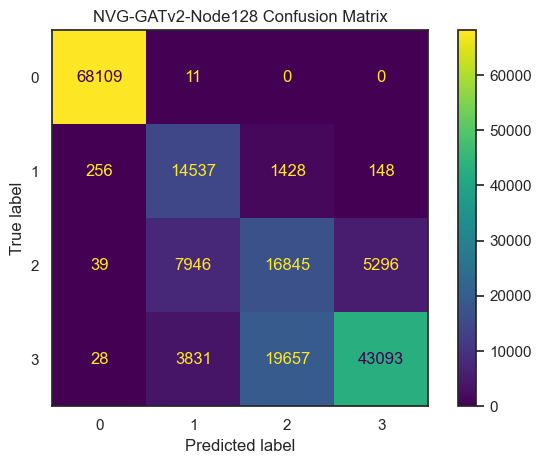

              precision    recall  f1-score   support

           0     0.9953    0.9998    0.9976     68120
           1     0.5522    0.8881    0.6810     16369
           2     0.4441    0.5592    0.4950     30126
           3     0.8878    0.6470    0.7485     66609

    accuracy                         0.7868    181224
   macro avg     0.7199    0.7735    0.7305    181224
weighted avg     0.8241    0.7868    0.7939    181224



Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3026 | Train Accuracy: 0.6902


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2228 | Train Accuracy: 0.7570


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1656 | Train Accuracy: 0.8076


Evaluating NVG-GATv2-Node64:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2-Node64 Evaluation
Validation Loss: 0.1662
Validation Accuracy: 0.7951
Validation Macro-F1: 0.7484


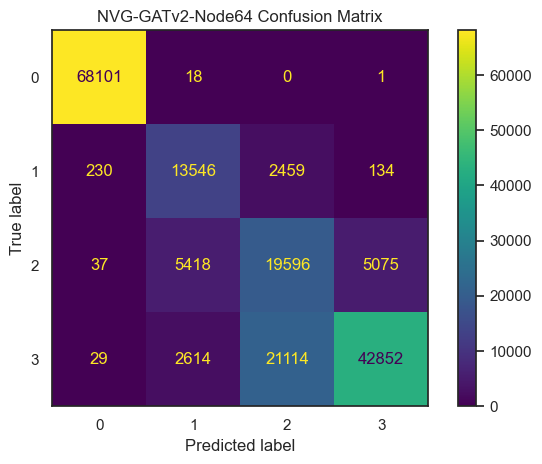

              precision    recall  f1-score   support

           0     0.9957    0.9997    0.9977     68120
           1     0.6272    0.8275    0.7136     16369
           2     0.4539    0.6505    0.5347     30126
           3     0.8916    0.6433    0.7474     66609

    accuracy                         0.7951    181224
   macro avg     0.7421    0.7803    0.7484    181224
weighted avg     0.8341    0.7951    0.8031    181224


NODE EMBEDDING ABLATION RESULTS
 Node Dimension  Macro Precision  Macro Recall  Macro F1-score
            128           0.7199        0.7735          0.7305
             64           0.7421        0.7803          0.7484


In [20]:
from sklearn.metrics import precision_score, recall_score


class GATv2(nn.Module):
    def __init__(self, num_classes=4, node_dim=128):
        super().__init__()
        self.node_dense = nn.Linear(3, node_dim)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATv2Conv(
            in_channels=node_dim, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Global MAX graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

ablation_results = []

for node_dim in [128, 64]:
    # Reproducibility
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    # Model
    model_nvg = GATv2(num_classes=4, node_dim=node_dim).to(device)

    # Original optimizer
    optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
    epochs = 10

    # Original training function
    train_losses_nvg, train_accuracies_nvg = train_model(
        model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
        device=device)

    # Original evaluation function
    results_nvg = evaluate_model(
        model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device,
        model_name=f"NVG-GATv2-Node{node_dim}")

    # Validation macro metrics
    macro_precision = precision_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_recall = recall_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_f1 = results_nvg["macro_f1"]
    ablation_results.append({
        "Node Dimension": node_dim,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1-score": macro_f1
    })

# ====================================
# FINAL COMPARISON
# ====================================
df_ablation = pd.DataFrame(ablation_results)
print("\nNODE EMBEDDING ABLATION RESULTS")
print("=" * 65)
print(df_ablation.round(4).to_string(index=False))


### Edge dimensions

Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.3000 | Train Accuracy: 0.6951


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2009 | Train Accuracy: 0.7743


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 03/10 | Train Loss: 0.1823 | Train Accuracy: 0.7912


... (12 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1613 | Train Accuracy: 0.8111


Evaluating NVG-GATv2-Node64:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2-Node64 Evaluation
Validation Loss: 0.1706
Validation Accuracy: 0.7842
Validation Macro-F1: 0.7300


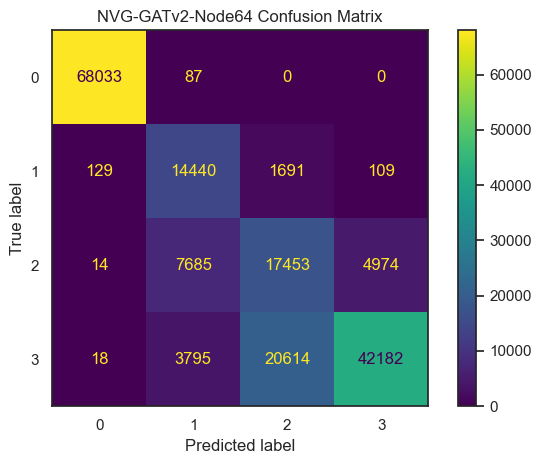

              precision    recall  f1-score   support

           0     0.9976    0.9987    0.9982     68120
           1     0.5552    0.8822    0.6815     16369
           2     0.4390    0.5793    0.4995     30126
           3     0.8925    0.6333    0.7409     66609

    accuracy                         0.7842    181224
   macro avg     0.7211    0.7734    0.7300    181224
weighted avg     0.8262    0.7842    0.7921    181224



Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2820 | Train Accuracy: 0.7053


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1973 | Train Accuracy: 0.7765


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1621 | Train Accuracy: 0.8099


Evaluating NVG-GATv2-Node64:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2-Node64 Evaluation
Validation Loss: 0.1744
Validation Accuracy: 0.7778
Validation Macro-F1: 0.7232


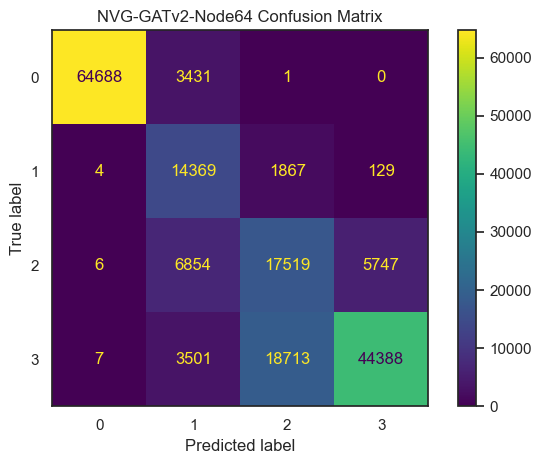

              precision    recall  f1-score   support

           0     0.9997    0.9496    0.9740     68120
           1     0.5104    0.8778    0.6454     16369
           2     0.4598    0.5815    0.5136     30126
           3     0.8831    0.6664    0.7596     66609

    accuracy                         0.7778    181224
   macro avg     0.7133    0.7688    0.7232    181224
weighted avg     0.8229    0.7778    0.7890    181224



Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2885 | Train Accuracy: 0.7009


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2046 | Train Accuracy: 0.7710


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1626 | Train Accuracy: 0.8103


Evaluating NVG-GATv2-Node64:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2-Node64 Evaluation
Validation Loss: 0.1761
Validation Accuracy: 0.7885
Validation Macro-F1: 0.7195


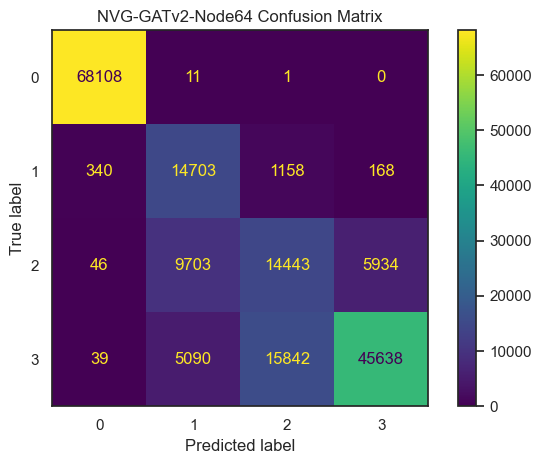

              precision    recall  f1-score   support

           0     0.9938    0.9998    0.9968     68120
           1     0.4983    0.8982    0.6410     16369
           2     0.4593    0.4794    0.4692     30126
           3     0.8821    0.6852    0.7712     66609

    accuracy                         0.7885    181224
   macro avg     0.7084    0.7657    0.7195    181224
weighted avg     0.8191    0.7885    0.7940    181224


EDGE EMBEDDING ABLATION RESULTS
 Edge Dimension  Macro Precision  Macro Recall  Macro F1-score
              4           0.7211        0.7734          0.7300
             16           0.7133        0.7688          0.7232
             32           0.7084        0.7657          0.7195


In [ ]:
class GATv2(nn.Module):
    def __init__(self, num_classes=4, edge_dim=8):
        super().__init__()
        self.node_dense = nn.Linear(3, 64)
        self.edge_dense = nn.Linear(1, edge_dim)
        self.gatv2conv1 = GATv2Conv(
            in_channels=64, out_channels=8, heads=6, concat=True, edge_dim=edge_dim, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(48)
        self.gatv2conv2 = GATv2Conv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=edge_dim, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Global MAX graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

ablation_results = []

for edge_dim in [4, 16, 32]:
    # Reproducibility
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    # Model
    model_nvg = GATv2(num_classes=4, edge_dim=edge_dim).to(device)

    # Original optimizer
    optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
    epochs = 10

    # Original training function
    train_losses_nvg, train_accuracies_nvg = train_model(
        model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
        device=device)

    # Original evaluation function
    results_nvg = evaluate_model(
        model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device,
        model_name=f"NVG-GATv2-Node{node_dim}")

    # Validation macro metrics
    macro_precision = precision_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_recall = recall_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_f1 = results_nvg["macro_f1"]
    ablation_results.append({
        "Edge Dimension": edge_dim,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1-score": macro_f1
    })

# ====================================
# FINAL COMPARISON
# ====================================
df_ablation = pd.DataFrame(ablation_results)
print("\nEDGE EMBEDDING ABLATION RESULTS")
print("=" * 65)
print(df_ablation.round(4).to_string(index=False))


In [23]:
baseline = {"Macro Precision": 0.7803, "Macro Recall": 0.7421, "Macro F1-score": 0.7484}
metrics = list(baseline.keys())

# Calculate differences from baseline
for metric in metrics:
    df_ablation[f"Delta {metric}"] = (df_ablation[metric] - baseline[metric])

# Check whether all three metrics improve
df_ablation["Better Than Baseline"] = (df_ablation[[f"Delta {m}" for m in metrics]].gt(0).all(axis=1))
print(df_ablation.round(4))

# Find configurations achieving the maximum of all three metrics
best_all_mask = (df_ablation[metrics].eq(df_ablation[metrics].max()).all(axis=1))

if best_all_mask.any():
    best_row = df_ablation.loc[best_all_mask].iloc[0]
    print("One edge dimension achieves the best scores in all metrics.")
else:
    # Fall back to highest F1, then Precision, then Recall
    best_row = df_ablation.sort_values(
        by=["Macro F1-score", "Macro Precision", "Macro Recall"], ascending=False).iloc[0]

    print("No single edge dimension is best in all three metrics.")
    print("Selecting based on Macro F1-score.")

best_edge_dim = best_row["Edge Dimension"]
print(f"\nBest Edge Dimension: {best_edge_dim}")
print(f"Macro Precision: {best_row["Macro Precision"]:.4f}")
print(f"Macro Recall:    {best_row["Macro Recall"]:.4f}")
print(f"Macro F1-score:  {best_row["Macro F1-score"]:.4f}")
print(f"Better than 8-edge baseline: {best_row["Better Than Baseline"]}")


   Edge Dimension  Macro Precision  Macro Recall  Macro F1-score  \
0               4           0.7211        0.7734          0.7300   
1              16           0.7133        0.7688          0.7232   
2              32           0.7084        0.7657          0.7195   

   Delta Macro Precision  Delta Macro Recall  Delta Macro F1-score  \
0                -0.0592              0.0313               -0.0184   
1                -0.0670              0.0267               -0.0252   
2                -0.0719              0.0236               -0.0289   

   Better Than Baseline  
0                 False  
1                 False  
2                 False  
One edge dimension achieves the best scores in all metrics.

Best Edge Dimension: 4
Macro Precision: 0.7211
Macro Recall:    0.7734
Macro F1-score:  0.7300
Better than 8-edge baseline: False


### head size

In [ ]:
class GATv2(nn.Module):
    def __init__(self, best_edge_dim, heads, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 64)
        self.edge_dense = nn.Linear(1, best_edge_dim)
        self.gatv2conv1 = GATv2Conv(
            in_channels=64, out_channels=8, heads=heads, concat=True, edge_dim=best_edge_dim,
            add_self_loops=True, fill_value=0.0)

        self.bn1 = nn.BatchNorm1d(8 * heads)
        self.gatv2conv2 = GATv2Conv(
            in_channels=8 * heads, out_channels=8, heads=heads, concat=True, edge_dim=best_edge_dim,
            add_self_loops=True, fill_value=0.0)

        self.bn2 = nn.BatchNorm1d(8 * heads)
        self.classifier = nn.Linear(8 * heads, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Global MAX graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

ablation_results = []
best_edge_dim = 8
for heads in [3, 4, 12]:
    # Reproducibility
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Model
    model_nvg = GATv2(best_edge_dim=best_edge_dim, heads=heads, num_classes=4).to(device)

    # Original optimizer
    optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
    epochs = 10

    # Original training function
    train_losses_nvg, train_accuracies_nvg = train_model(
        model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
        device=device)

    # Original evaluation function
    results_nvg = evaluate_model(
        model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device,
        model_name=f"NVG-GATv2-Heads{heads}")

    # Validation macro metrics
    macro_precision = precision_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_recall = recall_score(
        results_nvg["y_true"], results_nvg["y_pred"], average="macro", zero_division=0)

    macro_f1 = results_nvg["macro_f1"]
    ablation_results.append({
        "Heads": heads,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1-score": macro_f1
    })

df_ablation = pd.DataFrame(ablation_results)
print("\nATTENTION HEAD ABLATION RESULTS")
print("=" * 65)
print(df_ablation.round(4).to_string(index=False))

## GAT vs GATv2

GAT(
  (node_dense): Linear(in_features=3, out_features=64, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATConv(64, 8, heads=6)
  (bn1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (gatv2conv2): GATConv(48, 8, heads=6)
  (bn2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)


Epoch 1/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2808 | Train Accuracy: 0.7148


Epoch 2/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.1957 | Train Accuracy: 0.7800


Epoch 3/10:   0%|          | 0/2463 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 10/10:   0%|          | 0/2463 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.1683 | Train Accuracy: 0.8059


Evaluating NVG-GATv2:   0%|          | 0/708 [00:00<?, ?it/s]


NVG-GATv2 Evaluation
Validation Loss: 0.1651
Validation Accuracy: 0.8060
Validation Macro-F1: 0.7506


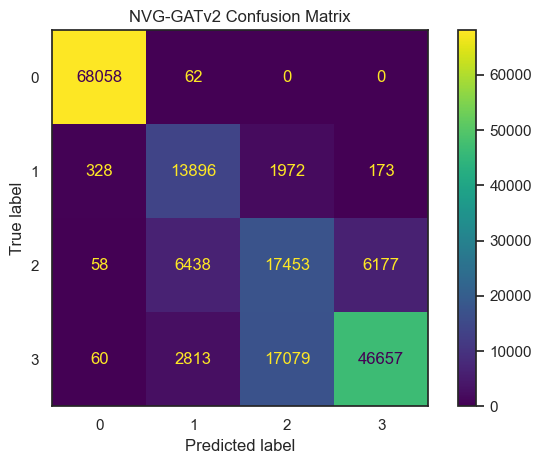

              precision    recall  f1-score   support

           0     0.9935    0.9991    0.9963     68120
           1     0.5987    0.8489    0.7022     16369
           2     0.4781    0.5793    0.5239     30126
           3     0.8802    0.7005    0.7801     66609

    accuracy                         0.8060    181224
   macro avg     0.7376    0.7820    0.7506    181224
weighted avg     0.8305    0.8060    0.8117    181224



In [ ]:
from torch_geometric.nn import GATConv

# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class GAT(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.node_dense = nn.Linear(3, 64)
        self.edge_dense = nn.Linear(1, 8)
        self.gatv2conv1 = GATConv(
            in_channels=64, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn1 = nn.LayerNorm(48)
        self.gatv2conv2 = GATConv(
            in_channels=48, out_channels=8, heads=6, concat=True, edge_dim=8, add_self_loops=True,
            fill_value=0.0)

        self.bn2 = nn.LayerNorm(48)
        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GAT block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GAT block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

model_nvg = GAT(num_classes=4).to(device)
print(model_nvg)
optimizer = torch.optim.Adam(model_nvg.parameters(), lr=0.001)
epochs = 10
train_losses_nvg, train_accuracies_nvg = train_model(
    model=model_nvg, loader=train_loader_nvg, optimizer=optimizer, criterion=criterion, epochs=epochs,
    device=device)

results_nvg = evaluate_model(
    model=model_nvg, loader=val_loader_nvg, criterion=criterion, device=device, model_name="NVG-GATv2")
